In [1]:

import pandas as pd

df = pd.read_csv("/content/dataset.csv", encoding="utf-8")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Dataset shape: (22000, 2)

Column names: ['Text', 'language']


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [2]:

# Task 1: Handle missing values and preprocess text

import re

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing text or language
df = df.dropna(subset=["Text", "language"]).copy()

# Remove empty text samples
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["Text"] != "") &
    (df["language"] != "")
].copy()

# Remove duplicate records
df = df.drop_duplicates(subset=["Text", "language"])

# Basic text preprocessing
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["Text"].apply(preprocess_text)

print("\nMissing values after cleaning:")
print(df[["clean_text", "language"]].isnull().sum())

print("\nDataset shape after cleaning:", df.shape)

print("\nCleaned sample records:")
display(df[["clean_text", "language"]].head())


Missing values before cleaning:
Text        0
language    0
dtype: int64

Missing values after cleaning:
clean_text    0
language      0
dtype: int64

Dataset shape after cleaning: (21858, 3)

Cleaned sample records:


,clean_text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuits...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [3]:

# Task 2: Tokenization and Padding

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Separate input text and output labels
X = df["clean_text"].values
y = df["language"].values

# Convert language names into numeric labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Create tokenizer using training text only
vocab_size = 15000
max_length = 100

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

# Convert text into integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to equal length
X_train_pad = pad_sequences(
    X_train_seq, maxlen=max_length, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=max_length, padding="post", truncating="post"
)

# Print results
print("Number of languages:", len(label_encoder.classes_))
print("Languages:", label_encoder.classes_)

print("\nTraining data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)

print("\nOriginal text:")
print(X_train[0])

print("\nNumerical sequence:")
print(X_train_seq[0][:20])

print("\nPadded sequence:")
print(X_train_pad[0])



Number of languages: 22
Languages: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']

Training data shape: (17486, 100)
Testing data shape: (4372, 100)

Original text:
또한 박상욱 전 해양경찰은 "그리고 세월호 앞에 학생들이 되게 위험하게 계속 소리지르고 해도 빨리 그쪽을 벗어나라고 소리질러도 애들이 어려서 철이 없는지 위험한지를 모르는건지위험을 감지를 못했던 것 같습니다" 라고 당시 피해학생들의 책임으로 돌리는듯한 발언을 하여 방청객들의 야유를 받았다

Numerical sequence:
[656, 1, 3094, 1, 634, 3095, 1, 1, 1, 1, 3886, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Padded sequence:
[ 656    1 3094    1  634 3095    1    1    1    1 3886    1    1    1
    1    1    1    1    1    1    1    1    1    1    1 3717    1 3528
  843    1    1    1    1 4843    1    1 4844    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0   

In [4]:

# Task 3: Build the LSTM model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Model parameters
vocab_size = 15000
embedding_dim = 64
num_classes = len(label_encoder.classes_)

# Create the LSTM model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.build(input_shape=(None, 100))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       960,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │         1,430 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 994,454 (3.79 MB)

 Trainable params: 994,454 (3.79 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:

# Task 3: Train the LSTM model

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 17s 64ms/step - accuracy: 0.4836 - loss: 1.8914 - val_accuracy: 0.7639 - val_loss: 0.8849
Epoch 2/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 15s 63ms/step - accuracy: 0.7512 - loss: 0.9694 - val_accuracy: 0.8605 - val_loss: 0.5736
Epoch 3/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.8585 - loss: 0.5508 - val_accuracy: 0.8931 - val_loss: 0.3895
Epoch 4/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.8885 - loss: 0.4097 - val_accuracy: 0.8742 - val_loss: 0.4168
Epoch 5/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.8945 - loss: 0.3362 - val_accuracy: 0.9097 - val_loss: 0.2612
Epoch 6/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - accuracy: 0.9207 - loss: 0.2445 - val_accuracy: 0.8513 - val_loss: 0.4845
Epoch 7/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 21s 64ms/step - accuracy: 0.9065 - loss: 0.3013 - val_accuracy: 0.5615 - val_loss: 1.9475


In [6]:

print("Epochs completed:", len(history.history["accuracy"]))
print("Final training accuracy:",
      round(history.history["accuracy"][-1] * 100, 2), "%")
print("Final validation accuracy:",
      round(history.history["val_accuracy"][-1] * 100, 2), "%")


Epochs completed: 7
Final training accuracy: 90.65 %
Final validation accuracy: 56.15 %


In [7]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict the test samples
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Calculate test metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("FINAL TEST RESULTS")
print("-" * 35)
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


FINAL TEST RESULTS
-----------------------------------
Accuracy : 0.9030 (90.30%)
Precision: 0.8984
Recall   : 0.9031
F1-score : 0.8924

Detailed Classification Report:
              precision    recall  f1-score   support

      Arabic       0.99      0.99      0.99       200
     Chinese       0.17      0.01      0.03       200
       Dutch       0.99      0.98      0.99       199
     English       0.83      0.96      0.89       200
    Estonian       0.99      0.91      0.95       200
      French       0.99      0.96      0.97       198
       Hindi       1.00      0.96      0.98       198
  Indonesian       0.96      0.97      0.96       195
    Japanese       0.47      0.94      0.63       200
      Korean       0.84      0.97      0.90       200
       Latin       0.97      0.91      0.94       191
     Persian       0.99      0.98      0.99       200
   Portugese       0.97      0.97      0.97       199
      Pushto       0.99      0.93      0.96       199
    Romanian       0

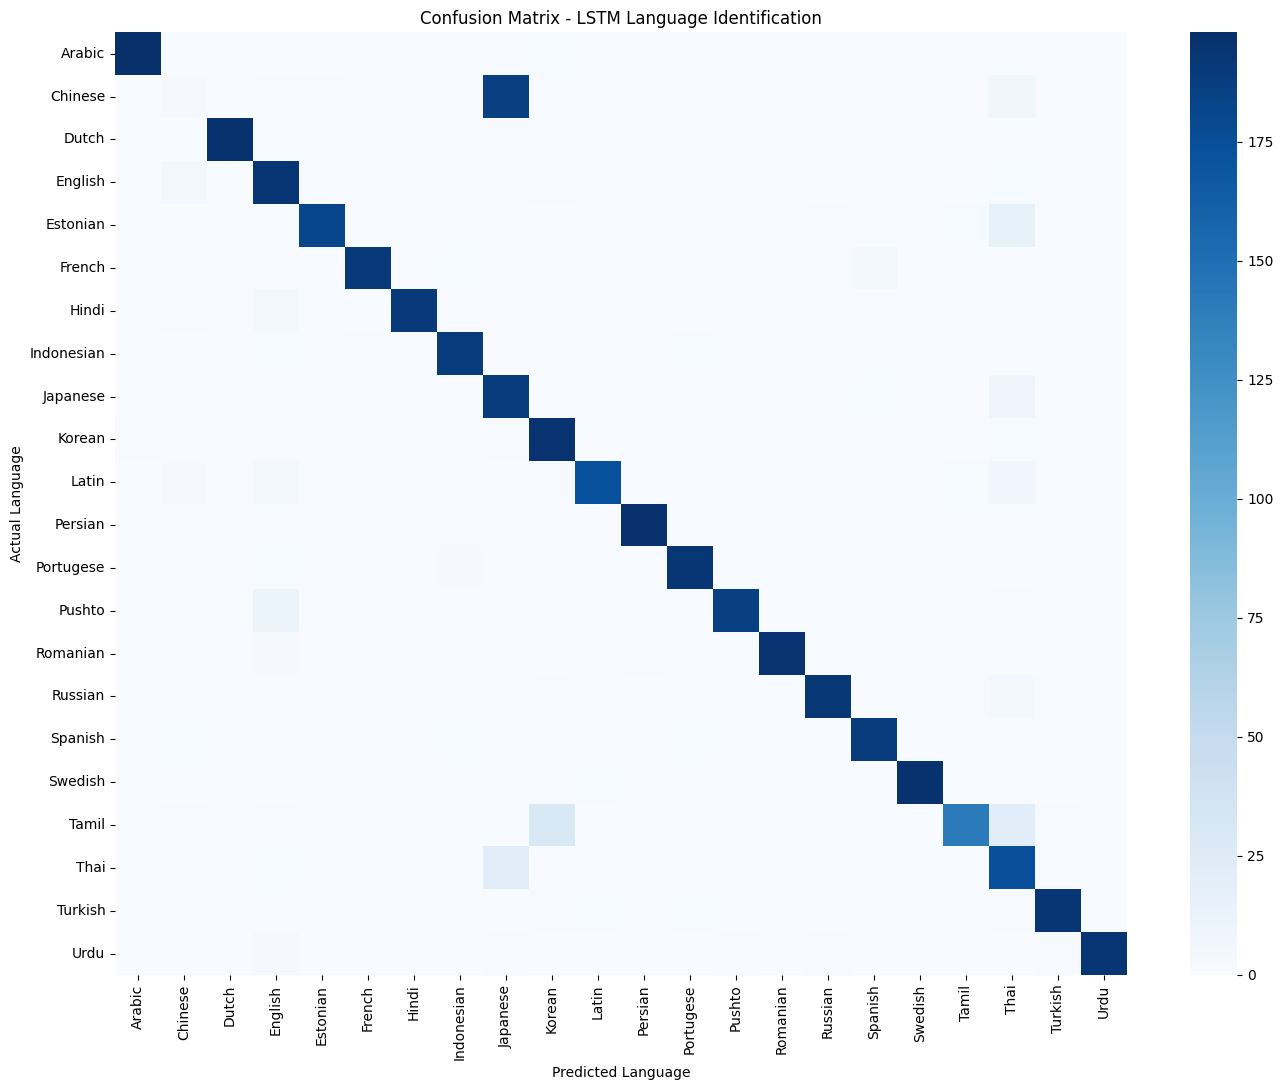

In [8]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

# Display the heatmap
plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - LSTM Language Identification")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [9]:

# Task 5B: Predict the language of five unseen text samples

unseen_samples = [
    "Good morning, how are you?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",
    "Ciao, come stai?"
]

# Convert sentences into numerical sequences
unseen_sequences = tokenizer.texts_to_sequences(unseen_samples)

# Pad sequences to the same length used during training
unseen_padded = pad_sequences(
    unseen_sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

# Predict the languages
probabilities = model.predict(unseen_padded, verbose=0)
predicted_ids = np.argmax(probabilities, axis=1)

# Display predictions
print("FIVE UNSEEN TEXT SAMPLE PREDICTIONS")
print("=" * 45)

for i, sentence in enumerate(unseen_samples):
    predicted_language = label_encoder.inverse_transform(
        [predicted_ids[i]]
    )[0]

    confidence = np.max(probabilities[i]) * 100

    print(f"\nSample {i + 1}: {sentence}")
    print(f"Predicted language: {predicted_language}")
    print(f"Confidence: {confidence:.2f}%")


FIVE UNSEEN TEXT SAMPLE PREDICTIONS

Sample 1: Good morning, how are you?
Predicted language: Chinese
Confidence: 22.27%

Sample 2: Bonjour, comment allez-vous?
Predicted language: Japanese
Confidence: 50.24%

Sample 3: Hola, ¿cómo estás?
Predicted language: Japanese
Confidence: 49.17%

Sample 4: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted language: Japanese
Confidence: 50.24%

Sample 5: Ciao, come stai?
Predicted language: Japanese
Confidence: 37.55%


In [ ]:

# Check the model's predictions on known test examples

for i in range(10):
    actual = label_encoder.inverse_transform([y_test[i]])[0]
    predicted = label_encoder.inverse_transform([y_pred[i]])[0]

    print("Text:", X_test[i][:100])
    print("Actual language:", actual)
    print("Predicted language:", predicted)
    print("-" * 50)


In [10]:
print("Colab is working!")


Colab is working!


In [11]:

print("Model available:", "model" in globals())
print("Tokenizer available:", "tokenizer" in globals())
print("Test data available:", "X_test" in globals())
print("Predictions available:", "y_pred" in globals())

Model available: True
Tokenizer available: True
Test data available: True
Predictions available: True


In [12]:

# Inspect 10 test samples and compare actual vs predicted languages

for i in range(10):
    actual = label_encoder.inverse_transform([int(y_test[i])])[0]
    predicted = label_encoder.inverse_transform([int(y_pred[i])])[0]

    print("Text:", X_test[i][:100])
    print("Actual language:", actual)
    print("Predicted language:", predicted)
    print("-" * 50)

Text: 一战结束后投资股票赚了大钱，成为百万富翁。后到好莱坞经营电影制片业。年回到波士顿。年美國總統選舉时，他支持富兰克林·德拉诺·罗斯福，年他被罗斯福总统任命为新成立的美國證券交易委員會主席，年又主持海事委
Actual language: Chinese
Predicted language: Japanese
--------------------------------------------------
Text: aidoma primei părți din sezonul drama totală reuniunea vedetelor acest sezon aduce în prim plan un s
Actual language: Romanian
Predicted language: Romanian
--------------------------------------------------
Text: iunie universitatea din lisabona a anunțat că o echipă internațională de astronomi a descoperit gala
Actual language: Romanian
Predicted language: Romanian
--------------------------------------------------
Text: ce genre a été nommé magnolia par le frère charles plumier - en lhonneur de pierre magnol - médecin 
Actual language: French
Predicted language: French
--------------------------------------------------
Text: na de oorlog werd zijn huwelijk met irma baulsir ontbonden in juli hertrouwde hij met jean emert dun
Actual language: Dutch
Predicted language: Dut

In [13]:

# Check the tokenizer and padding configuration

print("Tokenizer type:", type(tokenizer).__name__)
print("Vocabulary size:", len(tokenizer.word_index))
print("Maximum sequence length:", X_train_pad.shape[1])
print("Test sequence shape:", X_test_pad.shape)

print("\nFirst 10 tokenizer entries:")
print(list(tokenizer.word_index.items())[:10])

Tokenizer type: Tokenizer
Vocabulary size: 235697
Maximum sequence length: 100
Test sequence shape: (4372, 100)

First 10 tokenizer entries:
[('<OOV>', 1), ('de', 2), ('a', 3), ('en', 4), ('the', 5), ('la', 6), ('د', 7), ('in', 8), ('په', 9), ('و', 10)]


In [14]:

# Check the number of tokens retained by the model

vocab_size = 15000

print("Total vocabulary:", len(tokenizer.word_index))
print("Vocabulary supported by embedding:", vocab_size)

# Check token IDs in the training sequences
print("Largest token ID in training data:",
      max(max(seq, default=0) for seq in X_train))

# Check the percentage of test tokens outside the supported range
all_test_tokens = [token for seq in X_test for token in seq]

if all_test_tokens:
    outside = sum(token >= vocab_size for token in all_test_tokens)
    percentage = 100 * outside / len(all_test_tokens)

    print(f"Test tokens outside embedding range: {percentage:.2f}%")

Total vocabulary: 235697
Vocabulary supported by embedding: 15000
Largest token ID in training data: 𢙯


TypeError: '>=' not supported between instances of 'str' and 'int'

In [15]:

# Check vocabulary and token IDs correctly

vocab_size = 15000

print("Total vocabulary:", len(tokenizer.word_index))
print("Embedding vocabulary size:", vocab_size)

# Check numerical training sequences, not original text
train_tokens = [token for seq in X_train_seq for token in seq]
test_tokens = [token for seq in X_test_seq for token in seq]

print("\nLargest token ID in training sequences:",
      max(train_tokens, default=0))

print("Largest token ID in test sequences:",
      max(test_tokens, default=0))

# Count tokens outside the embedding's supported range
if test_tokens:
    outside = sum(token >= vocab_size for token in test_tokens)
    percentage = 100 * outside / len(test_tokens)

    print(f"Test tokens outside embedding range: {percentage:.2f}%")

Total vocabulary: 235697
Embedding vocabulary size: 15000

Largest token ID in training sequences: 14999
Largest token ID in test sequences: 14999
Test tokens outside embedding range: 0.00%


In [16]:

# Examine the top 3 predictions for each unseen sentence

unseen_samples = [
    "Good morning, how are you?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",
    "Ciao, come stai?"
]

unseen_sequences = tokenizer.texts_to_sequences(unseen_samples)

unseen_padded = pad_sequences(
    unseen_sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

probabilities = model.predict(unseen_padded, verbose=0)

for sentence, probs in zip(unseen_samples, probabilities):
    top3 = np.argsort(probs)[-3:][::-1]

    print("\nText:", sentence)
    for idx in top3:
        language = label_encoder.inverse_transform([idx])[0]
        print(f"{language}: {probs[idx] * 100:.2f}%")


Text: Good morning, how are you?
Chinese: 22.27%
Japanese: 21.99%
Romanian: 9.92%

Text: Bonjour, comment allez-vous?
Japanese: 50.24%
Chinese: 33.69%
Thai: 11.89%

Text: Hola, ¿cómo estás?
Japanese: 49.17%
Chinese: 35.99%
Thai: 8.24%

Text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Japanese: 50.24%
Chinese: 33.69%
Thai: 11.89%

Text: Ciao, come stai?
Japanese: 37.55%
Chinese: 33.83%
Thai: 6.96%


In [17]:

# Inspect tokenization of unseen sentences

for sentence in unseen_samples:
    sequence = tokenizer.texts_to_sequences([sentence])[0]

    print("\nText:", sentence)
    print("Token IDs:", sequence)
    print("Number of recognized tokens:", len(sequence))


Text: Good morning, how are you?
Token IDs: [6666, 1, 4973, 269, 1347]
Number of recognized tokens: 5

Text: Bonjour, comment allez-vous?
Token IDs: [1, 1, 1, 1]
Number of recognized tokens: 4

Text: Hola, ¿cómo estás?
Token IDs: [1, 1, 1]
Number of recognized tokens: 3

Text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Token IDs: [1, 1, 1, 1]
Number of recognized tokens: 4

Text: Ciao, come stai?
Token IDs: [1, 9693, 1]
Number of recognized tokens: 3


In [18]:

# Inspect the cleaned dataset and language distribution

print("Dataset shape:", df.shape)
print("\nText examples:")
print(df[["clean_text", "language"]].head(10).to_string(index=False))

print("\nNumber of samples per language:")
print(df["language"].value_counts().sort_index())

Dataset shape: (21858, 3)

Text examples:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          clean_text language
                                                                                                                                                                                                                                  klement gottwaldi surnukeha palsameeriti ning paigutati mausoleumi surnukeha oli aga liiga hilja ja oskamatult palsameeritud ning hakkas ilmutama lagunemise t

In [19]:

# Improved model: Character-level preprocessing

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

# Use the cleaned text and language labels
texts = df["clean_text"].astype(str).values
labels = df["language"].astype(str).values

# Encode language labels
char_label_encoder = LabelEncoder()
labels_encoded = char_label_encoder.fit_transform(labels)

# Split data before fitting the tokenizer
text_train, text_test, labels_train, labels_test = train_test_split(
    texts,
    labels_encoded,
    test_size=0.20,
    random_state=42,
    stratify=labels_encoded
)

# Character-level tokenizer
char_tokenizer = Tokenizer(
    char_level=True,
    lower=False,
    filters="",
    oov_token="<OOV>"
)

char_tokenizer.fit_on_texts(text_train)

char_vocab_size = len(char_tokenizer.word_index) + 1
char_max_length = 300

# Convert text into character sequences
char_train_seq = char_tokenizer.texts_to_sequences(text_train)
char_test_seq = char_tokenizer.texts_to_sequences(text_test)

# Pad or truncate sequences
char_train_pad = pad_sequences(
    char_train_seq,
    maxlen=char_max_length,
    padding="post",
    truncating="post"
)

char_test_pad = pad_sequences(
    char_test_seq,
    maxlen=char_max_length,
    padding="post",
    truncating="post"
)

print("Character vocabulary size:", char_vocab_size)
print("Training shape:", char_train_pad.shape)
print("Testing shape:", char_test_pad.shape)
print("Number of languages:", len(char_label_encoder.classes_))

Character vocabulary size: 6807
Training shape: (17486, 300)
Testing shape: (4372, 300)
Number of languages: 22


In [20]:

# Build the character-level LSTM model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

char_model = Sequential([
    Embedding(
        input_dim=char_vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    Bidirectional(LSTM(64)),
    Dropout(0.4),
    Dense(len(char_label_encoder.classes_), activation="softmax")
])

char_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

char_model.build(input_shape=(None, char_max_length))

char_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 300, 32)        │       217,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        49,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │         2,838 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 270,326 (1.03 MB)

 Trainable params: 270,326 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:

# Train the character-level LSTM

early_stopping_char = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

char_history = char_model.fit(
    char_train_pad,
    labels_train,
    epochs=8,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping_char],
    verbose=1
)

Epoch 1/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 73s 272ms/step - accuracy: 0.3293 - loss: 1.9772 - val_accuracy: 0.5483 - val_loss: 1.5127
Epoch 2/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 69s 279ms/step - accuracy: 0.5390 - loss: 1.3751 - val_accuracy: 0.5941 - val_loss: 1.1820
Epoch 3/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 68s 276ms/step - accuracy: 0.6157 - loss: 1.1206 - val_accuracy: 0.6118 - val_loss: 1.0748
Epoch 4/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 82s 275ms/step - accuracy: 0.6277 - loss: 1.1057 - val_accuracy: 0.6238 - val_loss: 1.0743
Epoch 5/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 83s 278ms/step - accuracy: 0.6516 - loss: 1.0149 - val_accuracy: 0.7015 - val_loss: 0.8898
Epoch 6/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 82s 280ms/step - accuracy: 0.6943 - loss: 0.8855 - val_accuracy: 0.6890 - val_loss: 0.9009
Epoch 7/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 84s 287ms/step - accuracy: 0.7215 - loss: 0.7861 - val_accuracy: 0.7764 - val_loss: 0.6372
Epoch 8/8
246/246 ━━━━━━━━━━━━━━━━━━━━ 80s 278ms/step - accuracy: 0.7210 - loss: 0.7766 - 

In [22]:

# Evaluate the character-level LSTM on unseen test data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

char_prob = char_model.predict(char_test_pad, verbose=0)
char_pred = np.argmax(char_prob, axis=1)

char_accuracy = accuracy_score(labels_test, char_pred)
char_precision = precision_score(
    labels_test, char_pred, average="macro", zero_division=0
)
char_recall = recall_score(
    labels_test, char_pred, average="macro", zero_division=0
)
char_f1 = f1_score(
    labels_test, char_pred, average="macro", zero_division=0
)

print("CHARACTER-LEVEL LSTM TEST RESULTS")
print("-" * 40)
print(f"Accuracy : {char_accuracy:.4f} ({char_accuracy*100:.2f}%)")
print(f"Precision: {char_precision:.4f}")
print(f"Recall   : {char_recall:.4f}")
print(f"F1-score : {char_f1:.4f}")

print("\nOriginal word-level LSTM test accuracy: 90.30%")
print(f"Character-level LSTM test accuracy: {char_accuracy*100:.2f}%")

CHARACTER-LEVEL LSTM TEST RESULTS
----------------------------------------
Accuracy : 0.7761 (77.61%)
Precision: 0.7809
Recall   : 0.7755
F1-score : 0.7584

Original word-level LSTM test accuracy: 90.30%
Character-level LSTM test accuracy: 77.61%


In [23]:

unseen_samples = [
    "Good morning, how are you?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",
    "Ciao, come stai?"
]

unseen_char_seq = char_tokenizer.texts_to_sequences(unseen_samples)

unseen_char_pad = pad_sequences(
    unseen_char_seq,
    maxlen=char_max_length,
    padding="post",
    truncating="post"
)

unseen_char_prob = char_model.predict(unseen_char_pad, verbose=0)
unseen_char_pred = np.argmax(unseen_char_prob, axis=1)

print("FIVE UNSEEN TEXT PREDICTIONS")
print("=" * 45)

for i, sentence in enumerate(unseen_samples):
    language = char_label_encoder.inverse_transform(
        [unseen_char_pred[i]]
    )[0]
    confidence = np.max(unseen_char_prob[i]) * 100

    print(f"\nSample {i + 1}: {sentence}")
    print(f"Predicted language: {language}")
    print(f"Confidence: {confidence:.2f}%")

FIVE UNSEEN TEXT PREDICTIONS

Sample 1: Good morning, how are you?
Predicted language: Portugese
Confidence: 23.04%

Sample 2: Bonjour, comment allez-vous?
Predicted language: Latin
Confidence: 46.21%

Sample 3: Hola, ¿cómo estás?
Predicted language: Portugese
Confidence: 34.70%

Sample 4: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted language: Tamil
Confidence: 99.84%

Sample 5: Ciao, come stai?
Predicted language: Latin
Confidence: 39.42%
